# Wind forecast accuracy — January 2026

How good was the national wind forecast a GB buyer could actually see when buying power ahead of time, and what can they rely on?

- **Data:** Elexon BMRS. Actual wind output (FUELHH, half-hourly) and the wind forecast (WINDFOR, hourly), January 2026, plus December 2025 for an honest out-of-sample test.
- **Rule:** for a target hour T and lead time H, we use the latest forecast published at or before T − H, the same rule the web app uses. The notebook imports the app's own code (`backend/app/selection.py`, `backend/app/metrics.py`) rather than copying it.
- **Labels:** **[in-sample]** means a number describes January using January data. **[out-of-sample]** means something was learned from December only and tested on January.
- **Run it:** `pip install -r analysis/requirements.txt`, then open this notebook from the `analysis/` folder and choose *Run all*. All times are UTC.

## Setup
Import the app's own selection rule and metrics, so every number here comes from the same code as the web app.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent  # this notebook lives in analysis/
sys.path.append(str(ROOT / "backend"))

from app.metrics import metrics_by_generation_level, metrics_by_lead_time, pair_with_actuals, summary_metrics
from app.selection import select_forecasts

ACTUAL_COLOUR = "#2a78d6"
FORECAST_COLOUR = "#eb6834"

Read one month's actuals and forecasts. January is the app's snapshot in `data/`; December is kept separately in `analysis/data/december/` so the app stays January-only.

In [2]:
# Read one month's actuals and forecasts (all times UTC).
def load_month(folder):
    actuals = pd.read_csv(folder / "actuals.csv", parse_dates=["startTime"])
    forecasts = pd.read_csv(folder / "forecasts.csv", parse_dates=["publishTime", "startTime"])
    return actuals, forecasts


jan_actuals, jan_forecasts = load_month(ROOT / "data")
dec_actuals, dec_forecasts = load_month(ROOT / "analysis" / "data" / "december")

# The target hours we score: every hour of each month (forecasts only exist on the hour).
JAN_HOURS = pd.date_range("2026-01-01 00:00", "2026-01-31 23:00", freq="h", tz="UTC")
DEC_HOURS = pd.date_range("2025-12-01 00:00", "2025-12-31 23:00", freq="h", tz="UTC")

For a lead time, put the forecast available that many hours ahead next to the actual for the same hour. Hours with no forecast (gaps) are left out.

In [3]:
# Forecast available `lead` hours ahead next to the actual, one row per target hour, gaps dropped.
def pairs_at(forecasts, actuals, hours, lead):
    selected = select_forecasts(forecasts, hours, lead)
    pairs = pair_with_actuals(selected, actuals)
    return pairs.dropna(subset=["forecast", "actual"])


jan_24 = pairs_at(jan_forecasts, jan_actuals, JAN_HOURS, 24)
dec_24 = pairs_at(dec_forecasts, dec_actuals, DEC_HOURS, 24)
print(f"January hours scored at 24 h: {len(jan_24)}; December: {len(dec_24)}")

January hours scored at 24 h: 744; December: 744


### Check: the notebook agrees with the web app

Before any analysis, recompute January at 24 h three ways: with plain pandas (a simple merge, not using `metrics.py`), with `metrics.py`, and by asking the web app's API. All three must match.

In [4]:
from fastapi.testclient import TestClient
from app.main import app

# 1. Plain pandas: merge the selected forecasts with the actuals ourselves.
selected = select_forecasts(jan_forecasts, JAN_HOURS, 24).reset_index()
merged = selected.merge(jan_actuals, on="startTime", suffixes=("_forecast", "_actual"))
plain_error = merged["generation_forecast"] - merged["generation_actual"]

# 2. The app's metrics module, and 3. the app's API.
module = summary_metrics(pair_with_actuals(select_forecasts(jan_forecasts, JAN_HOURS, 24), jan_actuals))
api = TestClient(app).get("/api/metrics?start=2026-01-01&end=2026-01-31&lead_hours=24").json()

check = pd.DataFrame(
    {
        "plain pandas": [plain_error.abs().mean(), plain_error.mean()],
        "metrics.py": [module["mae"], module["mean_forecast_minus_actual"]],
        "web app API": [api["mae"], api["mean_forecast_minus_actual"]],
    },
    index=["MAE (MW)", "forecast minus actual (MW)"],
).round(1)
assert (check.nunique(axis=1) == 1).all(), "the notebook and the app disagree"
check

,plain pandas,metrics.py,web app API
MAE (MW),2050.2,2050.2,2050.2
forecast minus actual (MW),1854.2,1854.2,1854.2


## 1. Data overview

How much data each month has, and whether anything is missing.

In [5]:
rows = []
for name, frame, step in [
    ("January actuals", jan_actuals, "30min"),
    ("January forecasts", jan_forecasts, "1h"),
    ("December actuals", dec_actuals, "30min"),
    ("December forecasts", dec_forecasts, "1h"),
]:
    targets = pd.DatetimeIndex(frame["startTime"].unique())
    expected = pd.date_range(targets.min(), targets.max(), freq=step)
    rows.append({
        "dataset": name,
        "rows": len(frame),
        "first target": targets.min(),
        "last target": targets.max(),
        "missing target times": len(expected.difference(targets)),
    })
pd.DataFrame(rows).set_index("dataset")

,rows,first target,last target,missing target times
dataset,,,,
January actuals,1632,2026-01-01 00:00:00+00:00,2026-02-03 23:30:00+00:00,0
January forecasts,14927,2026-01-01 00:00:00+00:00,2026-02-02 21:00:00+00:00,0
December actuals,1488,2025-12-01 00:00:00+00:00,2025-12-31 23:30:00+00:00,0
December forecasts,14384,2025-12-01 00:00:00+00:00,2025-12-31 23:00:00+00:00,0


When forecasts are published: count of publishes at each time of day in the January file.

In [6]:
publish_times = jan_forecasts["publishTime"].drop_duplicates().sort_values()
publish_times.dt.strftime("%H:%M").value_counts().sort_index().rename("publishes")

publishTime
02:30    33
04:30    33
07:30    33
09:30    33
11:30    32
12:25     1
15:30    33
18:30    33
22:30    33
Name: publishes, dtype: int64

How long a buyer can wait between two publishes.

In [7]:
waits = publish_times.diff().dropna()
waits.value_counts().sort_index().rename("times this wait occurred")

publishTime
0 days 02:00:00    98
0 days 02:55:00     1
0 days 03:00:00    66
0 days 03:05:00     1
0 days 04:00:00    97
Name: times this wait occurred, dtype: int64

Forecasts are hourly; actuals are half-hourly. Each publish also runs only until 21:00 two days later, which is why very long lead times have gaps.

In [8]:
print("Forecast target minutes:", sorted(jan_forecasts["startTime"].dt.minute.unique().tolist()))
print("Actual target minutes:  ", sorted(jan_actuals["startTime"].dt.minute.unique().tolist()))
last_target = jan_forecasts.groupby("publishTime")["startTime"].max()
days_ahead = (last_target.dt.normalize() - last_target.index.normalize()).dt.days
print("Each publish ends at:", last_target.dt.strftime("%H:%M").unique().tolist(), "| days after the publish day:", sorted(days_ahead.unique().tolist()))

Forecast target minutes: [0]
Actual target minutes:   [0, 30]
Each publish ends at: ['21:00'] | days after the publish day: [2]


The whole month: actual output and the forecast a buyer had 24 hours ahead.

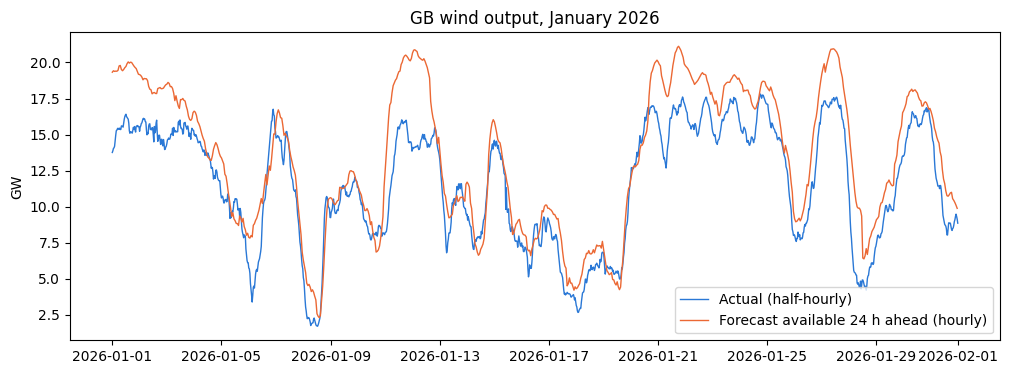

In [9]:
january = jan_actuals[jan_actuals["startTime"] < "2026-02-01"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(january["startTime"], january["generation"] / 1000, color=ACTUAL_COLOUR, linewidth=1, label="Actual (half-hourly)")
ax.plot(jan_24.index, jan_24["forecast"] / 1000, color=FORECAST_COLOUR, linewidth=1, label="Forecast available 24 h ahead (hourly)")
ax.set_ylabel("GW")
ax.set_title("GB wind output, January 2026")
ax.legend()
plt.show()

**Conclusions — data**
- Both months are complete: no missing half-hours of actual output and no missing forecast hours.
- Forecasts arrive 8 times a day at fixed times (02:30, 04:30, 07:30, 09:30, 11:30, 15:30, 18:30 and 22:30 UTC). The longest wait between two is 4 hours, and once in January a publish came at 12:25 instead of 11:30. So "the forecast available 24 h ahead" was in practice made about 25–27 hours ahead.
- Forecasts are hourly but output is measured every half-hour, so accuracy is scored on the hour only (744 hours in January). The :30 half-hours are shown in the app but not scored.

## 2. How accuracy changes with lead time **[in-sample]**

Score the same 744 January hours at every lead time from 1 to 48 hours, using the app's own function.

In [10]:
by_lead = metrics_by_lead_time(jan_forecasts, jan_actuals, JAN_HOURS, range(1, 49)).set_index("lead_hours")
by_lead.loc[[1, 6, 12, 18, 24, 30, 36, 42, 48], ["gaps", "mae", "mae_pct_of_mean_actual", "mean_forecast_minus_actual"]].round(1)

,gaps,mae,mae_pct_of_mean_actual,mean_forecast_minus_actual
lead_hours,,,,
1,0,1801.0,15.6,1595.7
6,0,1870.8,16.2,1683.2
12,0,1897.5,16.4,1704.0
18,0,1980.1,17.1,1790.8
24,0,2050.2,17.7,1854.2
30,0,2186.3,18.9,1897.2
36,0,2258.5,19.5,1950.7
42,0,2307.0,19.9,1939.3
48,155,2379.9,20.6,1879.3


Typical miss (MAE) and the average forecast-minus-actual, against lead time.

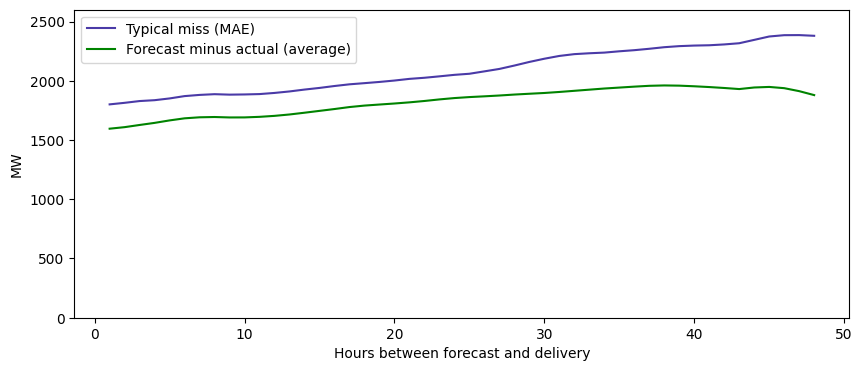

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(by_lead.index, by_lead["mae"], color="#4a3aa7", label="Typical miss (MAE)")
ax.plot(by_lead.index, by_lead["mean_forecast_minus_actual"], color="#008300", label="Forecast minus actual (average)")
ax.set_xlabel("Hours between forecast and delivery")
ax.set_ylabel("MW")
ax.set_ylim(0, 2600)
ax.legend()
plt.show()

Where does accuracy drop fastest? MAE growth per hour of extra lead time, in 12-hour blocks.

In [12]:
blocks = []
for first, last in [(1, 12), (12, 24), (24, 36), (36, 48)]:
    growth = by_lead.loc[last, "mae"] - by_lead.loc[first, "mae"]
    blocks.append({"lead hours": f"{first}-{last}", "MAE at start": by_lead.loc[first, "mae"], "MAE at end": by_lead.loc[last, "mae"], "MW per extra hour": growth / (last - first)})
pd.DataFrame(blocks).set_index("lead hours").round(1)

,MAE at start,MAE at end,MW per extra hour
lead hours,,,
1-12,1801.0,1897.5,8.8
12-24,1897.5,2050.2,12.7
24-36,2050.2,2258.5,17.4
36-48,2258.5,2379.9,10.1


The largest single one-hour steps.

In [13]:
by_lead["mae"].diff().nlargest(5).round(1).rename("MAE increase vs one hour shorter")

lead_hours
29    30.5
45    28.5
28    28.5
44    28.4
30    27.1
Name: MAE increase vs one hour shorter, dtype: float64

**Conclusions — lead time**
- The typical miss grows from 1,801 MW at 1 hour to 2,050 MW at 24 hours and 2,380 MW at 48 hours: from 16% to 18% to 21% of average output.
- It grows fastest between 24 and 36 hours ahead (about 17 MW per extra hour, twice the rate of the first 12 hours), with the biggest single steps at 28–30 hours ahead. From 44 hours the late-evening hours have no forecast at all (gaps), so 44–48 h numbers cover fewer hours.
- Lead time is not the main story: even 1 hour ahead the typical miss is 1.8 GW, and most of it is the steady offset in section 3.

## 3. The steady offset **[in-sample]**

Is it the same at every lead time? For each lead: the average forecast minus actual, the share of hours where the forecast was above the actual, and the typical miss once the average offset is taken out.

In [14]:
rows = []
for lead in [1, 6, 12, 24, 36, 48]:
    pairs = pairs_at(jan_forecasts, jan_actuals, JAN_HOURS, lead)
    offset = pairs["error"].mean()
    rows.append({
        "lead hours": lead,
        "forecast minus actual (MW)": offset,
        "share of hours forecast > actual": (pairs["error"] > 0).mean(),
        "MAE (MW)": pairs["error"].abs().mean(),
        "MAE with the average offset removed (MW)": (pairs["error"] - offset).abs().mean(),
    })
pd.DataFrame(rows).set_index("lead hours").round(2)

,forecast minus actual (MW),share of hours forecast > actual,MAE (MW),MAE with the average offset removed (MW)
lead hours,,,,
1,1595.69,0.87,1800.96,1264.13
6,1683.22,0.88,1870.84,1250.84
12,1703.99,0.87,1897.54,1293.85
24,1854.22,0.87,2050.24,1324.42
36,1950.71,0.83,2258.48,1530.53
48,1879.26,0.84,2379.89,1749.98


Does it grow with wind level? At 24 h, grouped by how much wind actually blew (the app's own breakdown).

In [15]:
metrics_by_generation_level(jan_24)[["level", "hours", "mae", "mean_forecast_minus_actual"]].round(0)

,level,hours,mae,mean_forecast_minus_actual
0,under 5 GW,52,2071.0,2019.0
1,5-10 GW,232,1534.0,1237.0
2,10-15 GW,246,2124.0,1934.0
3,15 GW and over,214,2520.0,2392.0


Do actuals flatten near a ceiling while forecasts don't? Each dot is one January hour at 24 h; the dashed line is where forecast = actual.

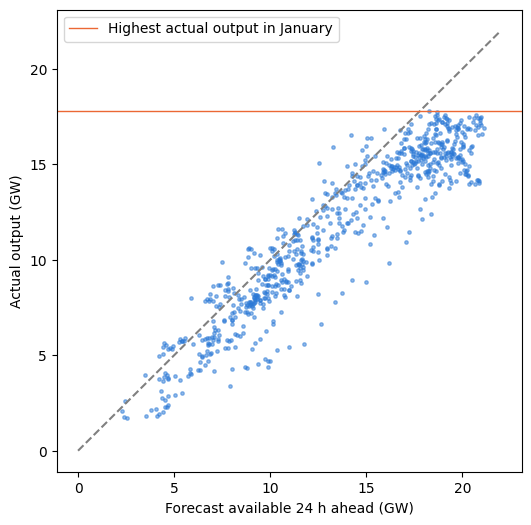

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(jan_24["forecast"] / 1000, jan_24["actual"] / 1000, s=6, alpha=0.5, color=ACTUAL_COLOUR)
ax.plot([0, 22], [0, 22], linestyle="--", color="grey")
ax.axhline(jan_actuals["generation"].max() / 1000, color=FORECAST_COLOUR, linewidth=1, label="Highest actual output in January")
ax.set_xlabel("Forecast available 24 h ahead (GW)")
ax.set_ylabel("Actual output (GW)")
ax.legend(loc="upper left")
plt.show()

The same picture as a table: for each band of the forecast, what actually happened.

In [17]:
bands = [0, 5000, 10000, 12500, 15000, 17500, 20000, 25000]
forecast_band = pd.cut(jan_24["forecast"], bands, right=False)
jan_24.groupby(forecast_band, observed=True)["actual"].agg(hours="size", mean_actual="mean", highest_actual="max").round(0)

,hours,mean_actual,highest_actual
forecast,,,
"[0, 5000)",34,3456.0,5652
"[5000, 10000)",185,7063.0,10622
"[10000, 12500)",120,9870.0,13194
"[12500, 15000)",85,12651.0,16519
"[15000, 17500)",98,14678.0,17088
"[17500, 20000)",175,15696.0,17805
"[20000, 25000)",47,15895.0,17593


How often each month went above 17.5 GW: in actual output, and in the forecast used at 24 h.

In [18]:
pd.DataFrame({
    "highest actual (MW)": [jan_actuals["generation"].max(), dec_actuals["generation"].max()],
    "hours actual >= 17.5 GW": [(jan_24["actual"] >= 17500).sum(), (dec_24["actual"] >= 17500).sum()],
    "hours forecast >= 17.5 GW": [(jan_24["forecast"] >= 17500).sum(), (dec_24["forecast"] >= 17500).sum()],
}, index=["January", "December"])

,highest actual (MW),hours actual >= 17.5 GW,hours forecast >= 17.5 GW
January,17805,8,222
December,18382,10,149


**Conclusions — the offset**
- It is almost the same at every lead time: the forecast is about 1.6–2.0 GW above actual output, and above it in 83–88% of hours. Even 1 hour ahead, when the weather is well known, the gap is 1.6 GW. Take the average offset out and the typical miss falls to about 1.3 GW at 24 h. So most of the "error" is a steady difference, not a weather miss.
- It grows with wind: about +1.2 GW when actual output is 5–10 GW, rising to +2.4 GW above 15 GW. (The calm band, under 5 GW, shows +2.0 GW, but over only 52 hours.)
- Actual output flattens near a ceiling while the forecast doesn't. January output never went above 17.8 GW, yet the 24 h forecast was above 17.5 GW in 222 hours, while output reached that level in only 8. When the forecast said 20 GW or more, output averaged 15.9 GW.
- This is **consistent with curtailment** (wind farms being paid to turn down when the grid can't take more power) **or with a coverage difference** between what WINDFOR forecasts and what FUELHH meters. **It is not proven here.** Confirming it would need the Balancing Mechanism's instructions to wind farms (e.g. Elexon's BOALF data).

## 4. A simple correction, tested honestly **[out-of-sample]**

Learn the offset from **December 2025 only**, then apply it to January. No January number is used to learn anything.

The correction can only use what a buyer knows at decision time, so the per-band version groups hours by the **forecast**, not by the actual output.

Step 1: the average offset in December, at 24 h.

In [19]:
december_offset = dec_24["error"].mean()
print(f"December forecast minus actual at 24 h: {december_offset:,.0f} MW over {len(dec_24)} hours")

December forecast minus actual at 24 h: 1,406 MW over 744 hours


Step 2: subtract it from every January forecast and compare the typical miss.

In [20]:
jan_mae = jan_24["error"].abs().mean()
corrected_error = jan_24["error"] - december_offset
print(f"January MAE at 24 h: {jan_mae:,.0f} MW before, {corrected_error.abs().mean():,.0f} MW after ({corrected_error.abs().mean() / jan_mae - 1:+.1%})")
print(f"January forecast minus actual after the correction: {corrected_error.mean():+,.0f} MW")

January MAE at 24 h: 2,050 MW before, 1,343 MW after (-34.5%)
January forecast minus actual after the correction: +448 MW


Step 3: one offset per forecast band, learned in December.

In [21]:
FORECAST_BANDS = [0, 5000, 10000, 15000, 100000]
BAND_NAMES = ["under 5 GW", "5-10 GW", "10-15 GW", "15 GW and over"]

dec_band = pd.cut(dec_24["forecast"], FORECAST_BANDS, labels=BAND_NAMES, right=False)
band_offsets = dec_24.groupby(dec_band, observed=False)["error"].agg(december_hours="size", december_offset="mean")
band_offsets.round(0)

,december_hours,december_offset
forecast,,
under 5 GW,36,-547.0
5-10 GW,208,85.0
10-15 GW,256,1037.0
15 GW and over,244,3207.0


Step 4: apply each band's December offset to the January hours in that band.

In [22]:
jan_band = pd.cut(jan_24["forecast"], FORECAST_BANDS, labels=BAND_NAMES, right=False)
band_corrected_error = jan_24["error"] - jan_band.map(band_offsets["december_offset"]).astype(float)

per_band = pd.DataFrame({
    "January hours": jan_band.value_counts(),
    "MAE before": jan_24["error"].abs().groupby(jan_band, observed=False).mean(),
    "MAE after": band_corrected_error.abs().groupby(jan_band, observed=False).mean(),
}).loc[BAND_NAMES].round(0)
print(f"January MAE at 24 h with per-band correction: {band_corrected_error.abs().mean():,.0f} MW ({band_corrected_error.abs().mean() / jan_mae - 1:+.1%})")
per_band

January MAE at 24 h with per-band correction: 1,253 MW (-38.9%)


,January hours,MAE before,MAE after
forecast,,,
under 5 GW,34,1155.0,1385.0
5-10 GW,185,1434.0,1389.0
10-15 GW,205,1450.0,1116.0
15 GW and over,320,2886.0,1249.0


The three options side by side.

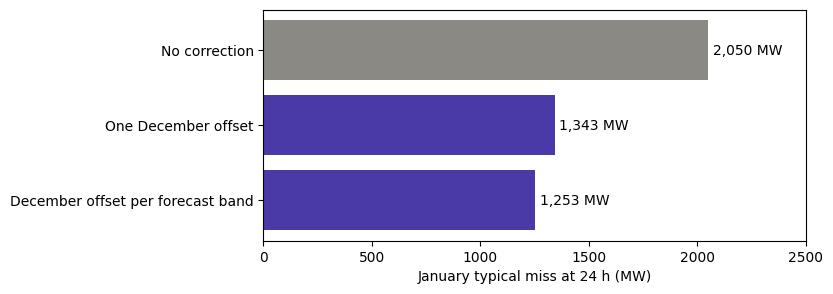

In [23]:
options = pd.Series({
    "No correction": jan_mae,
    "One December offset": corrected_error.abs().mean(),
    "December offset per forecast band": band_corrected_error.abs().mean(),
})
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(options.index, options.values, color=["#8a8984", "#4a3aa7", "#4a3aa7"])
for y, value in enumerate(options.values):
    ax.text(value + 20, y, f"{value:,.0f} MW", va="center")
ax.set_xlabel("January typical miss at 24 h (MW)")
ax.set_xlim(0, 2500)
ax.invert_yaxis()
plt.show()

Does the one-offset correction help at other lead times too? Each offset is learned in December at that lead.

In [24]:
rows = []
for lead in [1, 6, 12, 24, 36, 48]:
    december = pairs_at(dec_forecasts, dec_actuals, DEC_HOURS, lead)
    january = pairs_at(jan_forecasts, jan_actuals, JAN_HOURS, lead)
    offset = december["error"].mean()
    rows.append({
        "lead hours": lead,
        "December offset (MW)": offset,
        "January MAE before": january["error"].abs().mean(),
        "January MAE after": (january["error"] - offset).abs().mean(),
    })
pd.DataFrame(rows).set_index("lead hours").round(0)

,December offset (MW),January MAE before,January MAE after
lead hours,,,
1,1366.0,1801.0,1244.0
6,1391.0,1871.0,1242.0
12,1354.0,1898.0,1283.0
24,1406.0,2050.0,1343.0
36,1506.0,2258.0,1568.0
48,1415.0,2380.0,1777.0


**Conclusions — the correction**
- December's average offset at 24 h was +1.41 GW, smaller than January's +1.85 GW, but subtracting it still cuts January's typical miss from 2,050 MW to 1,343 MW (**−35%**), using no January data at all.
- One offset per forecast band does a little better overall (1,253 MW, **−39%**). The gain comes from windy hours (15 GW and over: 2,886 → 1,249 MW), but it makes the calm band worse (under 5 GW: 1,155 → 1,385 MW, only 34 hours). Don't correct calm hours without more data.
- It helps at every lead time (1 h: 1,801 → 1,244 MW; 48 h: 2,380 → 1,777 MW). January is still +0.45 GW after the correction, so the offset changes from month to month; an offset re-learned from the last few weeks would track it better than a fixed number.

## 5. What a buyer can rely on

The question a buyer actually asks: *"When the forecast 24 hours ahead says X GW, how much can I count on?"* "Count on" here means the output reached in 9 hours out of 10: the 10th percentile of actual output.

**[in-sample]** January described by its own data: for each forecast band, the output reached 9 hours in 10.

In [25]:
BUYER_BANDS = [0, 5000, 10000, 15000, 20000, 100000]
BUYER_NAMES = ["under 5 GW", "5-10 GW", "10-15 GW", "15-20 GW", "20 GW and over"]

jan_buyer_band = pd.cut(jan_24["forecast"], BUYER_BANDS, labels=BUYER_NAMES, right=False)
buyer = jan_24.groupby(jan_buyer_band, observed=False)["actual"].agg(
    hours="size",
    typical_actual="median",
    at_least_9_in_10=lambda actual: actual.quantile(0.10),
)
buyer.round(0)

,hours,typical_actual,at_least_9_in_10
forecast,,,
under 5 GW,34,3408.0,1861.0
5-10 GW,185,7545.0,4661.0
10-15 GW,205,10856.0,8631.0
15-20 GW,273,15414.0,13932.0
20 GW and over,47,15972.0,14152.0


**[out-of-sample]** Would a buyer have known this in advance? Learn the 9-in-10 level per band from December, then count how often January output actually reached it (the target is 90%).

In [26]:
dec_buyer_band = pd.cut(dec_24["forecast"], BUYER_BANDS, labels=BUYER_NAMES, right=False)
december_floor = dec_24.groupby(dec_buyer_band, observed=False)["actual"].quantile(0.10)

reached = jan_24["actual"] >= jan_buyer_band.map(december_floor).astype(float)
pd.DataFrame({
    "December 9-in-10 level (MW)": december_floor.round(0),
    "January hours": jan_buyer_band.value_counts(),
    "share of January hours that reached it": reached.groupby(jan_buyer_band, observed=False).mean().round(2),
}).loc[BUYER_NAMES]

,December 9-in-10 level (MW),January hours,share of January hours that reached it
forecast,,,
under 5 GW,2721.0,34,0.59
5-10 GW,5954.0,185,0.69
10-15 GW,8430.0,205,0.91
15-20 GW,12629.0,273,0.96
20 GW and over,14570.0,47,0.77


**[out-of-sample]** An even simpler rule: count on a fixed share of the forecast. Learn the share from December (the 10th percentile of actual ÷ forecast), test it on January.

In [27]:
december_share = (dec_24["actual"] / dec_24["forecast"]).quantile(0.10)
january_ok = jan_24["actual"] >= december_share * jan_24["forecast"]
print(f"Learned in December: count on {december_share:.0%} of the 24 h forecast.")
print(f"In January, output reached that level in {january_ok.mean():.0%} of hours (target 90%).")
january_ok.groupby(jan_buyer_band, observed=False).mean().round(2).rename("share of January hours that reached it")

Learned in December: count on 73% of the 24 h forecast.
In January, output reached that level in 89% of hours (target 90%).


forecast
under 5 GW        0.62
5-10 GW           0.83
10-15 GW          0.94
15-20 GW          0.96
20 GW and over    0.72
Name: share of January hours that reached it, dtype: float64

**Conclusions — what a buyer can rely on**
- **[in-sample]** In January, when the 24 h forecast said 15–20 GW, output was at least 13.9 GW 9 hours in 10; at 10–15 GW, at least 8.6 GW; at 5–10 GW, only at least 4.7 GW. The lower the forecast, the bigger the share of it you can't count on.
- **[out-of-sample]** The simplest usable rule: **count on about 73% of the 24 h forecast**. Learned from December, it held in 89% of January hours, close to the 9-in-10 target. It is reliable for 10–20 GW forecasts (94–96% of hours) and weaker for calm forecasts under 5 GW (62%) and very high ones over 20 GW (72%, where the ceiling from section 3 bites).
- December's per-band levels transferred well for 10–20 GW forecasts (91–96% of January hours) but not for calm ones (59–69%). January's calm spells fell further short of the forecast than December's.

## 6. Limits

- **Small sample.** One month to test (January 2026) and one month to learn from (December 2025), both in the same winter. Wind, demand and curtailment behave differently in summer; the offset and the "73%" rule may not hold then.
- **In-sample numbers are descriptions, not predictions.** Sections 2, 3 and the first table in section 5 describe January using January data. Only section 4 and the out-of-sample tables in section 5 test something learned beforehand.
- **The cause of the offset is not established.** Curtailment or a coverage difference fit the evidence (steady across lead times, larger in high wind, a ceiling on actual output), but we have not checked Balancing Mechanism curtailment data.
- **Scope.** National total only, hourly comparison (the :30 half-hours are not scored), and from 44 hours ahead the late-evening hours have no forecast, so long-lead numbers cover fewer hours.
- **A fixed lead time is a simplification.** Real day-ahead buying happens at a fixed auction time; for example, Nord Pool's N2EX GB day-ahead auction closes at 09:50 UK time the day before delivery ([Nord Pool](https://support.nordpoolgroup.com/support/solutions/articles/8000088463-about-the-day-ahead-gb-auction)). Scoring at a fixed 24 h is a close stand-in, not the exact decision time.

**With more time:** test across a full year and every season; re-learn the offset each week from the most recent weeks and test it going forward; bring in curtailment data (BOALF) to test the curtailment explanation directly; score the actual day-ahead auction time; and turn the "count on" rule into a proper forecast range (for example a 10th–90th percentile band per forecast level and lead time) shown in the app.